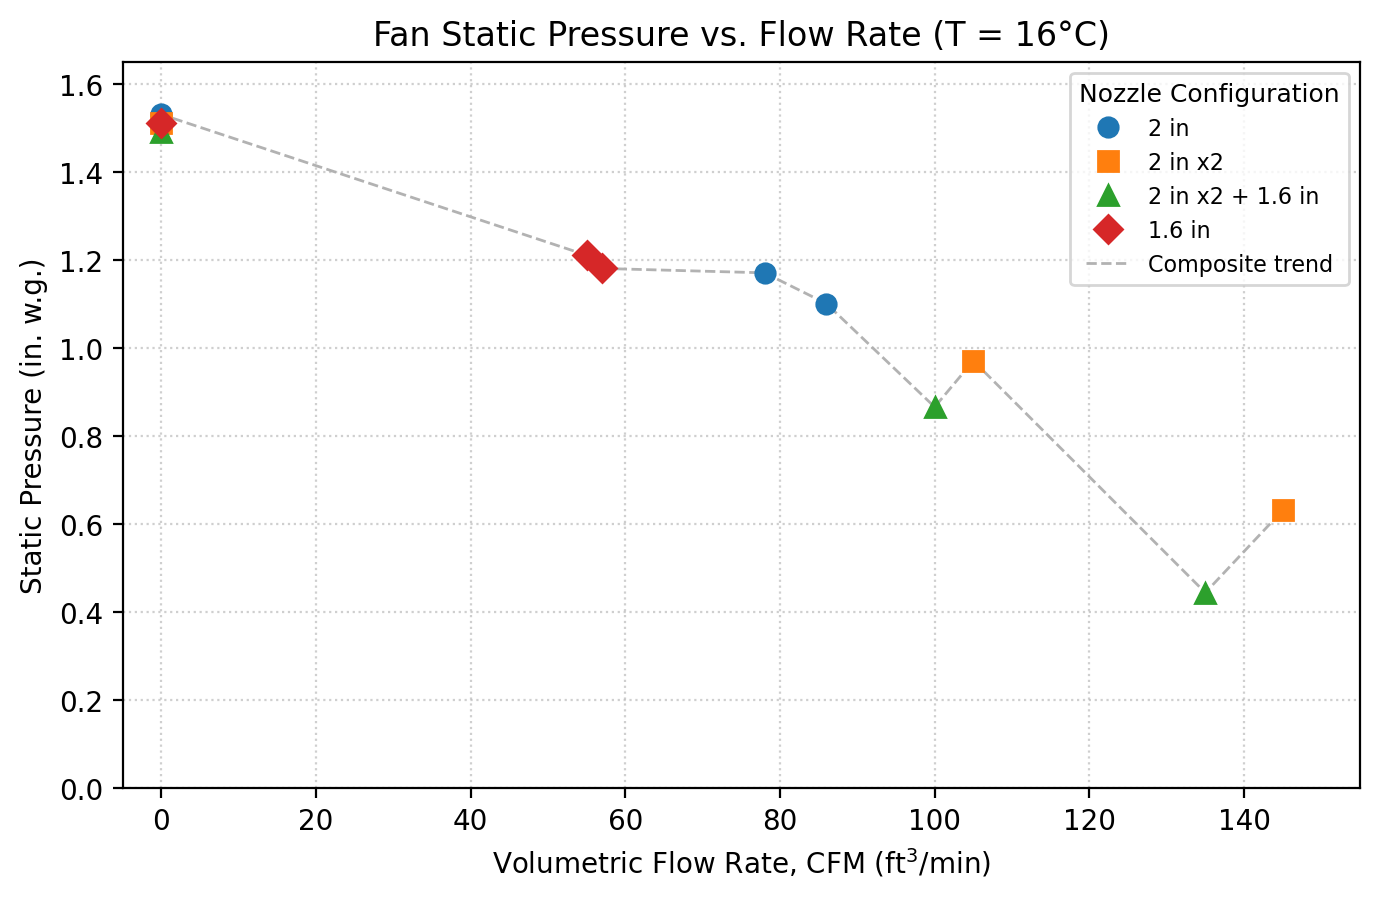

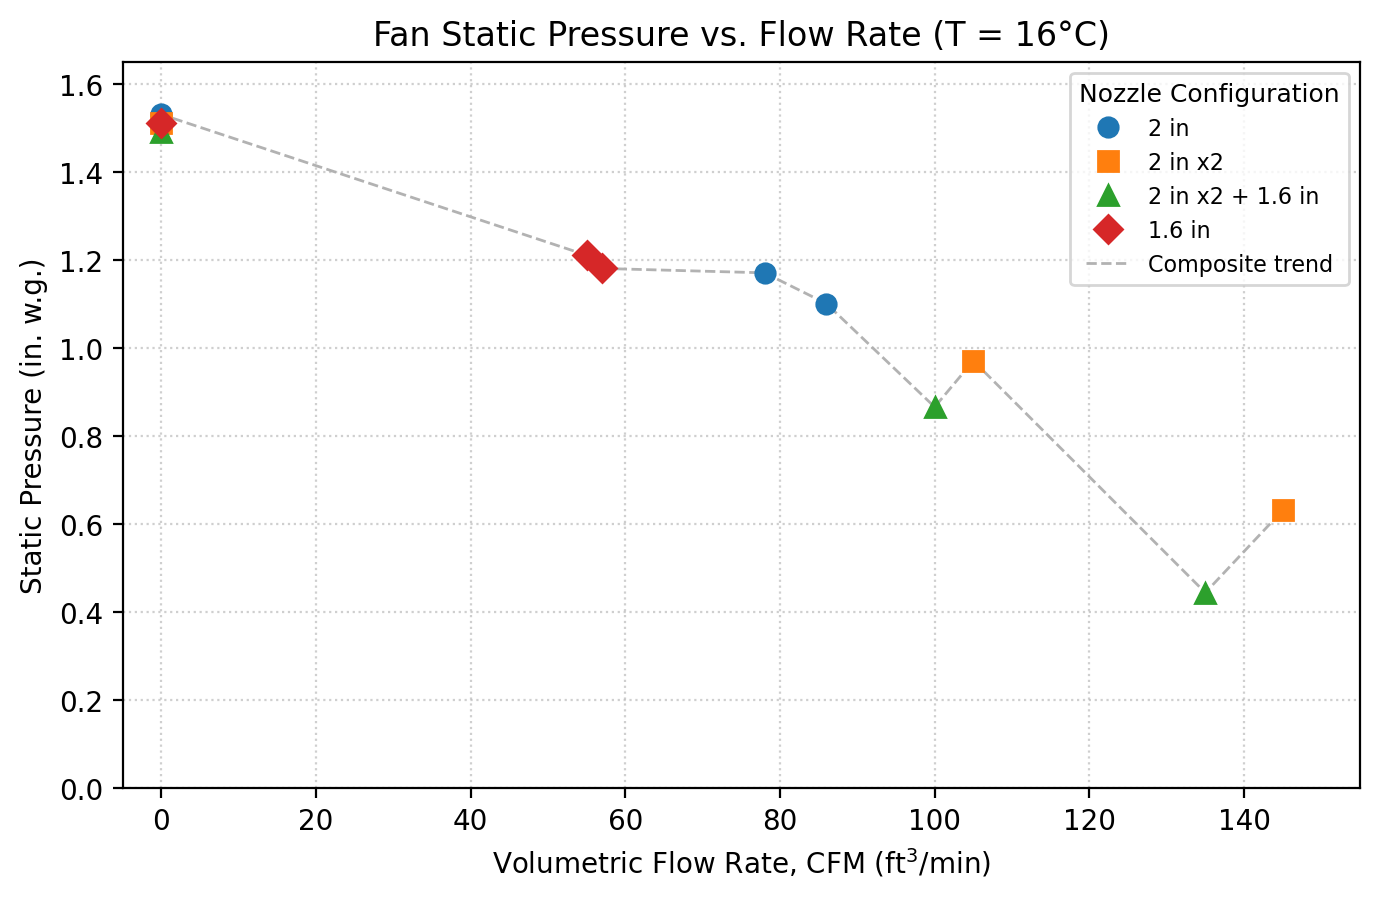

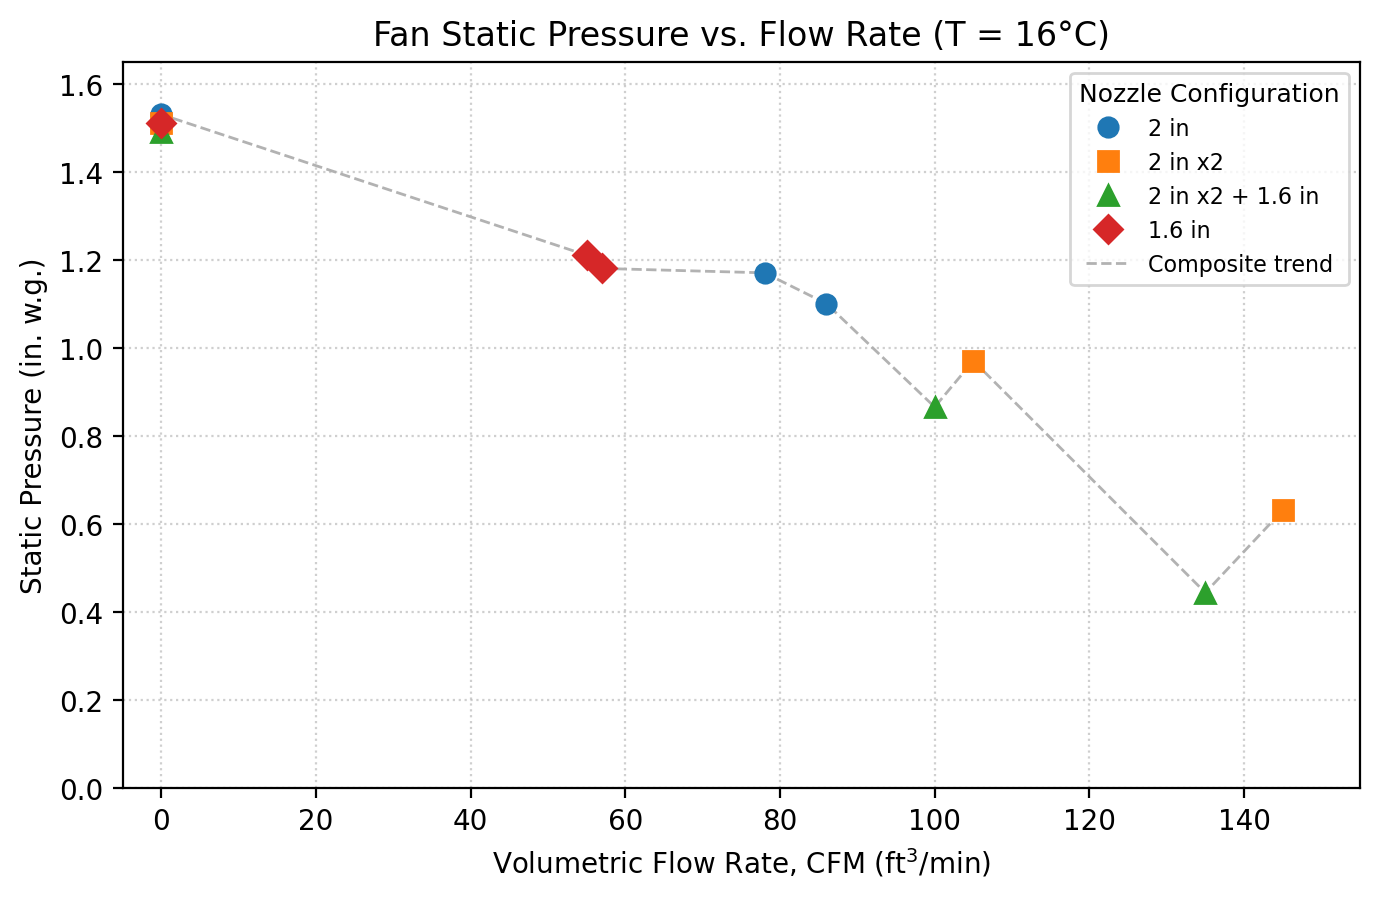

In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt

# Data: (CFM, Static Pressure in H2O, nozzle configuration label)
data = [
    (0, 1.53, "2 in"),
    (78, 1.17, "2 in"),
    (86, 1.10, "2 in"),
    (0, 1.51, "2 in x2"),
    (105, 0.97, "2 in x2"),
    (145, 0.63, "2 in x2"),
    (0, 1.49, "2 in x2 + 1.6 in"),
    (100, 0.865, "2 in x2 + 1.6 in"),
    (135, 0.443, "2 in x2 + 1.6 in"),
    (0, 1.51, "1.6 in"),
    (55, 1.21, "1.6 in"),
    (57, 1.18, "1.6 in"),
]

configs = {}
for cfm, sp, label in data:
    configs.setdefault(label, []).append((cfm, sp))

markers = {"2 in": "o", "2 in x2": "s", "2 in x2 + 1.6 in": "^", "1.6 in": "D"}
colors = {"2 in": "#1f77b4", "2 in x2": "#ff7f0e", "2 in x2 + 1.6 in": "#2ca02c", "1.6 in": "#d62728"}

fig, ax = plt.subplots(figsize=(7.0, 4.6), dpi=200)

for label, pts in configs.items():
    pts = sorted(pts)
    xs = [p[0] for p in pts]
    ys = [p[1] for p in pts]
    ax.plot(xs, ys, marker=markers[label], color=colors[label], linestyle="None",
             markersize=7, label=label)

# Combined trend curve using all points sorted by CFM
all_pts = sorted(set((cfm, sp) for cfm, sp, _ in data))
xs_all = [p[0] for p in all_pts]
ys_all = [p[1] for p in all_pts]
ax.plot(xs_all, ys_all, color="gray", linewidth=1.0, linestyle="--", alpha=0.6,
         label="trend", zorder=0)

ax.set_xlabel("Volumetric Flow Rate, CFM (ft$^3$/min)")
ax.set_ylabel("Static Pressure (in. w.g.)")
ax.set_title("Fan Static Pressure vs. Flow Rate (T = 16°C)")
ax.grid(True, linestyle=":", alpha=0.6)
ax.set_xlim(-5, 155)
ax.set_ylim(0, 1.65)
ax.legend(title="Nozzle Configuration", fontsize=8, title_fontsize=9, loc="upper right")
fig.tight_layout()
plt.show()
